# Notebook 05 — Comparación entre aprendizaje supervisado y no supervisado, y conclusiones

**Qué hace este notebook:** une los resultados de los notebooks 03 y 04, responde las **8 preguntas comparativas** del enunciado con datos y propone una recomendación para una aplicación real. Los resultados de los otros notebooks se leen de la carpeta `resultados/`.

> Requisito: haber ejecutado antes los notebooks 03 y 04 (generan los archivos de `resultados/`).

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sys.path.insert(0, str(RAIZ / 'src'))
from preprocesamiento import (cargar_datos, dividir_train_test, construir_preprocesador, matriz_conducta,
                              NUMERICAS, CATEGORICAS, BINARIAS, CONDUCTA, OBJETIVO, SEMILLA, MESES_ORDEN)

In [2]:
import json
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

df = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(df)

sup_cv = pd.read_csv(RES / 'metricas_supervisado_cv.csv').set_index('modelo')
sup_test = pd.read_csv(RES / 'metricas_supervisado_test.csv').set_index('modelo')
cfg = json.load(open(RES / 'modelo_final.json'))
clu = pd.read_csv(RES / 'metricas_clustering.csv', index_col=0)
perf = pd.read_csv(RES / 'perfiles_segmentos.csv', index_col=0)
seg_rev = pd.read_csv(RES / 'segmentos_vs_revenue.csv', index_col=0)
segmento = pd.read_csv(RES / 'segmento_por_sesion.csv', index_col=0)['segmento']
sel_k = pd.read_csv(RES / 'kmeans_seleccion_k.csv', index_col=0)
print('Modelo supervisado elegido:', cfg['mejor_modelo'], '| umbral:', round(cfg['umbral'], 3))

Modelo supervisado elegido: Random Forest | umbral: 0.673


## 1. Los dos enfoques lado a lado

In [3]:
mejor = cfg['mejor_modelo']
fila_sup = sup_test.loc[mejor]
mejor_clu = clu['silhouette'].idxmax()

lado = pd.DataFrame({
    'Supervisado': [f'Predecir si la sesion termina en compra (Revenue)', mejor, 'Usa Revenue para aprender',
                    f'PR-AUC {fila_sup["pr_auc"]:.2f} · ROC-AUC {fila_sup["roc_auc"]:.2f} · F1 {fila_sup["f1"]:.2f} · Recall {fila_sup["recall"]:.2f}',
                    'Una probabilidad de compra por sesion'],
    'No supervisado': ['Descubrir tipos de visitantes segun su navegacion', 'K-Means, Gaussian Mixture y Aglomerativo', 'NO usa Revenue (solo para interpretar)',
                       f'Silhouette {clu.loc["K-Means", "silhouette"]:.2f} · Davies-Bouldin {clu.loc["K-Means", "davies_bouldin"]:.2f} (K-Means, k=4)',
                       '4 segmentos con perfil de conducta'],
}, index=['Pregunta', 'Algoritmo(s)', 'Etiqueta', 'Resultado clave', 'Entrega'])
lado

,Supervisado,No supervisado
Pregunta,Predecir si la sesion termina en compra (Revenue),Descubrir tipos de visitantes segun su navegacion
Algoritmo(s),Random Forest,"K-Means, Gaussian Mixture y Aglomerativo"
Etiqueta,Usa Revenue para aprender,NO usa Revenue (solo para interpretar)
Resultado clave,PR-AUC 0.75 · ROC-AUC 0.94 · F1 0.69 · Recall ...,Silhouette 0.41 · Davies-Bouldin 0.85 (K-Means...
Entrega,Una probabilidad de compra por sesion,4 segmentos con perfil de conducta


## 2. ¿Se complementan? La probabilidad de compra por segmento
Se reconstruye el modelo supervisado elegido (mismos hiperparámetros del notebook 03), se calcula la **probabilidad de compra en el test** y se compara con los segmentos descubiertos sin etiquetas.

In [4]:
from preprocesamiento import construir_preprocesador
clases = {'Random Forest': RandomForestClassifier, 'Gradient Boosting': HistGradientBoostingClassifier, 'Regresion logistica': LogisticRegression}
estimador = clases[mejor]().set_params(**cfg['params'])
modelo = Pipeline([('prep', construir_preprocesador(True)), ('modelo', estimador)]).fit(X_train, y_train)
prob = pd.Series(modelo.predict_proba(X_test)[:, 1], index=X_test.index, name='prob_compra')
print(f'Control: PR-AUC en test = {average_precision_score(y_test, prob):.3f} (notebook 03: {fila_sup["pr_auc"]:.3f})')

t = pd.DataFrame({'prob': prob, 'real': y_test, 'segmento': segmento.reindex(X_test.index)})
t['marcada'] = t['prob'] >= cfg['umbral']
por_seg = t.groupby('segmento').agg(sesiones_test=('real', 'size'), compra_real=('real', 'mean'), prob_media=('prob', 'mean'),
                                    marcadas_por_el_modelo=('marcada', 'mean')).sort_values('compra_real', ascending=False)
por_seg

Control: PR-AUC en test = 0.751 (notebook 03: 0.751)


,sesiones_test,compra_real,prob_media,marcadas_por_el_modelo
segmento,,,,
Navegantes intensos,442,0.265,0.449,0.299
Exploradores con cuenta,844,0.192,0.353,0.237
Consultores rapidos de producto,990,0.103,0.176,0.095
Rebotadores,165,0.006,0.027,0.000


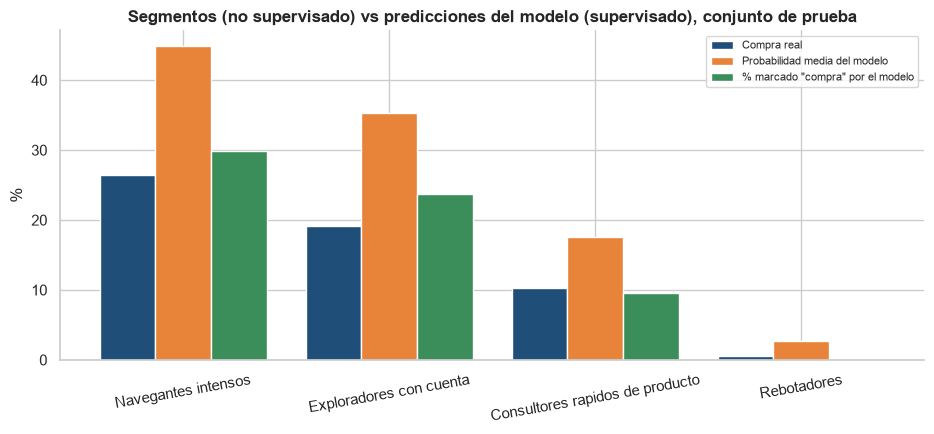

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(por_seg)); w = .27
ax.bar(x - w, por_seg['compra_real'] * 100, w, color=AZUL, label='Compra real')
ax.bar(x, por_seg['prob_media'] * 100, w, color=NARANJA, label='Probabilidad media del modelo')
ax.bar(x + w, por_seg['marcadas_por_el_modelo'] * 100, w, color=VERDE, label='% marcado "compra" por el modelo')
ax.set_xticks(x); ax.set_xticklabels(por_seg.index, rotation=10); ax.set_ylabel('%')
ax.set_title('Segmentos (no supervisado) vs predicciones del modelo (supervisado), conjunto de prueba'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / '05_segmentos_vs_modelo.png', dpi=150, bbox_inches='tight'); plt.show()

**Qué muestra esta integración**
- El modelo supervisado **reproduce el orden de los segmentos**: asigna la probabilidad más alta a los *Navegantes intensos* (0,45), luego a los *Exploradores con cuenta* (0,35), los *Consultores* (0,18) y casi cero a los *Rebotadores* (0,03). Dos enfoques independientes, uno con etiqueta y otro sin ella, **coinciden en quién tiene más intención**.
- La probabilidad media del modelo es **mayor que la tasa de compra real** en todos los segmentos (p. ej. 0,45 contra 26,5 %). Esto es esperable porque el modelo se entrenó con **pesos de clase** (`balanced_subsample`): sus probabilidades sirven para **ordenar** sesiones, pero **no están calibradas**. Antes de usarlas como probabilidades reales habría que calibrarlas.
- Dentro de cada segmento todavía hay variación: el modelo marca como "compra" al 29,9 % de los Navegantes intensos y al 23,7 % de los Exploradores, aunque compraron 26,5 % y 19,2 %. Es decir, **el modelo supervisado agrega información que el segmento solo no tiene** (permite elegir *a quién* dentro del segmento).

## 3. Respuestas a las 8 preguntas del enunciado


**1. ¿Qué problema resuelve cada componente?**
El **supervisado** responde *"¿esta sesión terminará en compra?"*: tiene una respuesta correcta conocida (`Revenue`) y se mide por qué tan bien la acierta. El **no supervisado** responde *"¿qué tipos de visitantes hay?"*: no tiene respuesta correcta, busca estructura y se juzga por la cohesión de los grupos y su utilidad para el negocio.

**2. ¿Qué algoritmos se eligieron y por qué?**
Supervisado: **regresión logística** (línea base interpretable), **Random Forest** y **Gradient Boosting** (captan no linealidades e interacciones y toleran colas largas sin escalado). No supervisado: **K-Means** (rápido, interpretable), **Gaussian Mixture** (grupos elípticos y asignación probabilística) y **Aglomerativo Ward** (determinista y sin semilla). Cada uno asume una forma distinta de estructura, lo que permite verificar la robustez de los hallazgos.

**3. ¿Qué dificultades hubo?**
(a) El **desbalance** (15,6 %): accuracy inservible, hubo que usar PR-AUC, pesos de clase y umbral. (b) **`PageValues`** con riesgo de fuga: obligó a una ablación y a excluirla del agrupamiento. (c) **Duplicados** que habrían contaminado la división. (d) **Colinealidad** entre conteos y duraciones (VIF hasta 7,4). (e) En el agrupamiento, la **elección de k** no es unívoca (silhouette favorece k = 3; DB y CH, k = 4) y el BIC del GMM no tiene mínimo.

**4. ¿El modelo supervisado identificó los casos de interés?**
**Sí, con un matiz importante.** El Random Forest elegido detecta el **72,8 % de las compras (recall)** con una **precision de 65,3 %**, **F1 = 0,688**, **PR-AUC = 0,751** (4,8 veces el azar) y ROC-AUC = 0,936. **Pero más de la mitad de ese desempeño depende de `PageValues`**: sin ella la PR-AUC cae a 0,37 (2,4 veces el azar). El modelo funciona bien *si* esa variable está disponible a tiempo.

**5. ¿El no supervisado descubrió algo no evidente?**
**Sí.** (1) Existe un grupo claramente separado de **rebotadores** (6,5 % de las sesiones y solo 4 compras). (2) La variable **"visitar páginas administrativas"** separa dos grupos de navegación larga con tasas de compra muy distintas frente a los consultores rápidos. (3) El grupo que **más compras aporta en total (44 %) no es el de mayor tasa**. Ninguno de estos patrones se veía en el EDA univariado.

**6. ¿Qué relación hay entre las etiquetas y los grupos?**
Los grupos **no coinciden** con la etiqueta como partición (ARI = 0,011; NMI = 0,025), pero sí **la ordenan**: la tasa de compra pasa de 0,5 % a 10,6 %, 20,1 % y 23,9 % según el compromiso del grupo. Es decir, la forma de navegar **se asocia con comprar sin determinarlo**: dentro de cada grupo todavía hay compradores y no compradores, y por eso se necesita el modelo supervisado.

**7. ¿Qué información se conserva o se pierde al reducir dimensiones?**
En el notebook 02, el PCA de las 73 columnas conserva solo el **43,4 %** de la varianza con 2 componentes (80 % requiere 10): se **pierde mucho** y la compra no se ve en 2D. En el notebook 04, con las 8 variables de conducta, 2 componentes conservan el **73,7 %**; t-SNE conserva vecindades locales pero **pierde las distancias globales y los tamaños**. Por eso las proyecciones se usaron **solo para visualizar** y las decisiones se tomaron sobre el espacio completo.

**8. ¿Qué enfoque se recomendaría?**
Ver la sección siguiente.

## 4. Recomendación para una aplicación real y estrategias de negocio


### Recomendación: usar los dos enfoques, cada uno para lo que hace bien

| Necesidad | Enfoque | Por qué |
|---|---|---|
| **Actuar durante la sesión** (cupón, chat de ayuda) | **Random Forest (o Gradient Boosting) con umbral bajo** | Entrega una probabilidad por sesión y ordena bien (PR-AUC 0,75 con `PageValues`). Se usaría un umbral menor al de F1 porque la falsa alarma es barata |
| **Diseñar estrategias y presupuesto por tipo de visitante** | **K-Means (k = 4)** | Estable (ARI 0,997), interpretable y no depende de una etiqueta |
| **Priorizar a quién ofrecer qué** | **Ambos combinados**: segmento + puntaje del modelo | El segmento da el *contexto* y el modelo elige *a quién dentro del segmento* |

**Condición previa (crítica):** verificar con el equipo de datos **si `PageValues` está disponible antes de que el visitante compre**. Si no lo está, el modelo útil es el **"sin `PageValues`"** (PR-AUC ≈ 0,37), que sigue siendo 2,4 veces mejor que el azar pero mucho menos preciso; en ese caso la segmentación gana peso como herramienta principal.

### Estrategias de negocio por segmento

| Segmento | Tamaño · tasa de compra | Estrategia propuesta |
|---|---|---|
| **Navegantes intensos** | 18 % · 23,9 % | Alta intención: **asistencia en vivo**, guías de compra y comparadores; intervenir primero en las sesiones que el modelo marca como "compra" |
| **Exploradores con cuenta** | 34 % · 20,1 % (44 % de las compras) | El grupo más valioso en volumen de compras: **recordatorios y mensajes personalizados** cuando abandonan sin comprar; proteger la experiencia de cuenta |
| **Consultores rápidos de producto** | 41 % · 10,6 % | Mucho volumen y poca compra: **reducir fricción** (fichas claras, recomendaciones, envío visible); una oferta suave de primera compra |
| **Rebotadores** | 7 % · 0,5 % | **No gastar en retención**: mejorar la página de aterrizaje y revisar las fuentes de tráfico que traen visitas que se van de inmediato |

**Estacionalidad:** la tasa de compra pasa de 1,7 % en febrero y ~10 % entre marzo y junio a **25,5 % en noviembre**: concentrar campañas en **octubre–noviembre**.

## 5. Limitaciones


- **Un solo comercio y un año de datos:** los resultados pueden no generalizarse a otras tiendas ni a otros años; faltan enero y abril.
- **`PageValues` y fuga de información:** no se puede verificar desde el dataset cuándo se calcula; condiciona el desempeño del modelo supervisado.
- **Cada sesión es de un usuario distinto:** no se puede estudiar la conducta de un mismo cliente en el tiempo (retención, recompra).
- **Pocos positivos en test (382):** las métricas tienen intervalos amplios (el recall tiene ±4,5 puntos); las diferencias de 0,003 entre RF y GB no son concluyentes.
- **Probabilidades no calibradas** por el uso de pesos de clase: sirven para ordenar, no para estimar riesgos.
- **Costos supuestos:** el análisis de umbrales usa relaciones de costo ilustrativas, no reales.
- **El agrupamiento depende de decisiones del analista:** variables elegidas, transformación `log1p`, k = 4. Otra elección (por ejemplo, k = 3) daría otros segmentos. Además K-Means supone grupos esféricos y los datos no lo son del todo.
- **Variables de Google Analytics** (`BounceRates`, `ExitRates`, `PageValues`) son promedios por página: pierden el detalle de la sesión real.
- **Es observacional:** los segmentos y las importancias muestran asociaciones, no causas; que un grupo compre más no significa que una intervención dirigida a él funcione.